# Sequential E2T2 on the peg-slide: experiments

The method is `Sequential_E2T2_peg_slide_2D.ipynb`, loaded once below; editing it during a run does not affect the run.

**Claim.** On the peg-slide with the block displaced beyond the slot's clearance, the expanding target with forgetting reaches the goal more often than E2T2. The taught world and offsets within the clearance are reported as well.

**Measures.** The headline is the **success share**: trials that reach the goal within `MAX_STEPS`. Every failure is a **slip-out** (inserted, the barrier removed, but no goal) or **never inserted** (the barrier still stands). The share of time in the dead end is reported beside them. A sequence's trials share an offset, so the standard errors are taken over sequences.

**Experiments.**
1. Ablation: static or expanding target, with or without forgetting.
2. Forgetting horizon: $T_{\mathrm{f}}$ at half and twice its derived value.
3. Offset sweep: E2T2 against the expanding target with forgetting, from the taught world to $\pm 0.11$.

Each experiment writes its results to `final/output/` as soon as it ends.

In [1]:
%%capture method
%run -i Sequential_E2T2_peg_slide_2D.ipynb

In [2]:
import time
from multiprocessing import Pool
from pathlib import Path
from types import SimpleNamespace

import numpy as np
from IPython import get_ipython
from matplotlib import pyplot as plt

m = SimpleNamespace(**get_ipython().user_ns)  # the method notebook's names

N_TRIALS, N_SEQ, N_SEQ_SWEEP = 5, 6, 3  # quick run; the long run is 10, 20, 10
WORKERS = 16  # of 24 cores, so other work on the machine stays responsive
OUT = Path("../../output")
OUT.mkdir(exist_ok=True)
draw = np.random.default_rng(3)
# The displaced sequences of the ablation; a quick run uses the first N_SEQ.
DISPLACED = draw.choice([-1.0, 1.0], 20) * draw.uniform(0.08, 0.11, 20)


# (N_TRIALS, 5): steps, success, inserted, dead-end entries, dead-end time share
def summarise(expanding, lam, offset, seq):
    return np.array(
        [
            [r["steps"], r["success"], r["inserted"], r["dead_ends"], r["dead_share"]]
            for r in m.run_sequence(expanding, lam, offset, seq, N_TRIALS)
        ],
        float,
    )


# settings: name -> (expanding, lambda); one sequence per offset
def experiment(name, settings, offsets):
    t0 = time.time()
    jobs = [(*s, off, seq) for s in settings.values() for seq, off in enumerate(offsets)]
    with Pool(WORKERS) as pool:
        out = pool.starmap(summarise, jobs)
    n = len(offsets)
    res = {k: np.array(out[i * n : (i + 1) * n]) for i, k in enumerate(settings)}
    np.savez(OUT / f"{name}_{N_TRIALS}trials_{n}seq.npz", offsets=offsets, **res)
    print(f"{name}: {len(jobs)} sequences in {(time.time() - t0) / 60:.1f} min")
    return res


# (n_seq, n_trials, 5) -> per sequence: success, slip-out, never inserted, dead-end time
def shares(R):
    success, inserted = R[:, :, 1], R[:, :, 2]
    return np.stack(
        [
            success.mean(1),
            (inserted * (1 - success)).mean(1),
            (1 - inserted).mean(1),
            R[:, :, 4].mean(1),
        ],
        axis=1,
    )


def table(res, offsets):
    for side, sel in (("all", np.full(len(offsets), True)), ("+", offsets > 0), ("-", offsets < 0)):
        if not sel.any():
            continue
        print(f"offsets {side} ({sel.sum()} sequences)")
        for k, R in res.items():
            s = shares(R[sel])
            se = s.std(0, ddof=1) / np.sqrt(len(s)) if len(s) > 1 else np.full(4, np.nan)
            print(
                f"  {k:26s} success {s[:, 0].mean():.2f} +- {se[0]:.2f}, slip-out {s[:, 1].mean():.2f}, "
                f"never inserted {s[:, 2].mean():.2f}, dead-end time {s[:, 3].mean():.2f}"
            )

### 1. Ablation
Which half does the work: the target that expands with the phase, the statistic that forgets, or both. All four settings on the same displaced sequences and noise.

In [3]:
ABLATION = {
    "E2T2": (False, 1.0),
    "static + forgetting": (False, m.lam_f),
    "expanding, no forgetting": (True, 1.0),
    "expanding + forgetting": (True, m.lam_f),
}
offsets_d = DISPLACED[:N_SEQ]
abl = experiment("ablation", ABLATION, offsets_d)
table(abl, offsets_d)

ablation: 24 sequences in 3.7 min
offsets all (6 sequences)
  E2T2                       success 0.33 +- 0.10, slip-out 0.17, never inserted 0.50, dead-end time 0.69
  static + forgetting        success 0.60 +- 0.09, slip-out 0.27, never inserted 0.13, dead-end time 0.49
  expanding, no forgetting   success 0.10 +- 0.07, slip-out 0.10, never inserted 0.80, dead-end time 0.64
  expanding + forgetting     success 0.60 +- 0.13, slip-out 0.33, never inserted 0.07, dead-end time 0.38
offsets + (2 sequences)
  E2T2                       success 0.50 +- 0.30, slip-out 0.50, never inserted 0.00, dead-end time 0.52
  static + forgetting        success 0.40 +- 0.20, slip-out 0.60, never inserted 0.00, dead-end time 0.15
  expanding, no forgetting   success 0.10 +- 0.10, slip-out 0.30, never inserted 0.60, dead-end time 0.56
  expanding + forgetting     success 0.40 +- 0.40, slip-out 0.60, never inserted 0.00, dead-end time 0.30
offsets - (4 sequences)
  E2T2                       success 0.25 +-

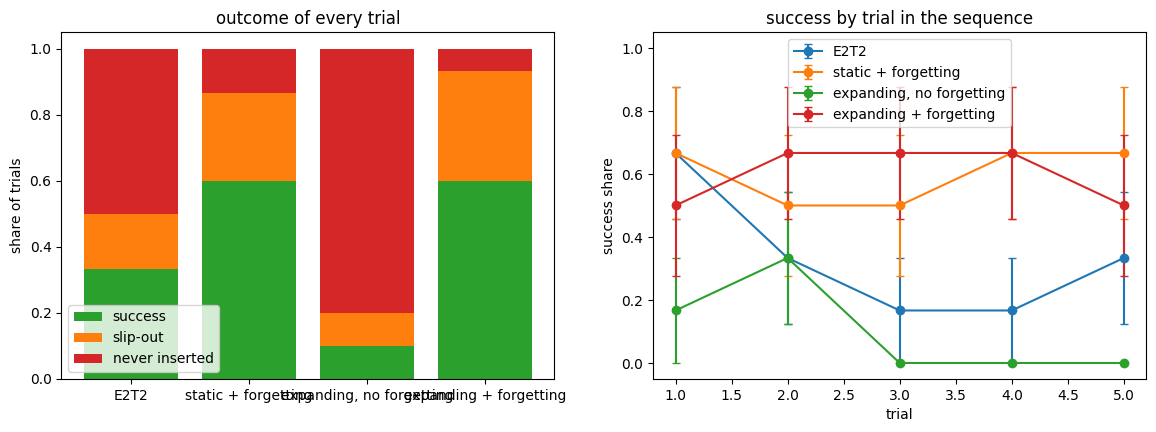

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
names = list(abl)
s = np.array([shares(abl[k]).mean(0) for k in names])
bottom = np.zeros(len(names))
for j, (lbl, col) in enumerate(
    (("success", "tab:green"), ("slip-out", "tab:orange"), ("never inserted", "tab:red"))
):
    ax[0].bar(names, s[:, j], bottom=bottom, color=col, label=lbl)
    bottom += s[:, j]
ax[0].set(ylabel="share of trials", title="outcome of every trial")
ax[0].legend()
for k in names:
    R = abl[k][:, :, 1]
    ax[1].errorbar(
        range(1, N_TRIALS + 1),
        R.mean(0),
        R.std(0, ddof=1) / np.sqrt(len(R)),
        marker="o",
        capsize=3,
        label=k,
    )
ax[1].set(
    xlabel="trial",
    ylabel="success share",
    ylim=(-0.05, 1.05),
    title="success by trial in the sequence",
)
ax[1].legend()
plt.show()

### 2. Forgetting horizon
$T_{\mathrm{f}}$ is derived, the half-life equal to the master's duration. Half and twice it, against the ablation's $\times 1$ and no forgetting ($\times \infty$), with the expanding target.

forgetting_horizon: 12 sequences in 2.3 min
offsets all (6 sequences)
  T_f x0.5                   success 0.10 +- 0.07, slip-out 0.87, never inserted 0.03, dead-end time 0.22
  T_f x1                     success 0.60 +- 0.13, slip-out 0.33, never inserted 0.07, dead-end time 0.38
  T_f x2                     success 0.40 +- 0.14, slip-out 0.27, never inserted 0.33, dead-end time 0.51
  no forgetting              success 0.10 +- 0.07, slip-out 0.10, never inserted 0.80, dead-end time 0.64
offsets + (2 sequences)
  T_f x0.5                   success 0.20 +- 0.20, slip-out 0.80, never inserted 0.00, dead-end time 0.21
  T_f x1                     success 0.40 +- 0.40, slip-out 0.60, never inserted 0.00, dead-end time 0.30
  T_f x2                     success 0.40 +- 0.40, slip-out 0.40, never inserted 0.20, dead-end time 0.40
  no forgetting              success 0.10 +- 0.10, slip-out 0.30, never inserted 0.60, dead-end time 0.56
offsets - (4 sequences)
  T_f x0.5                   succe

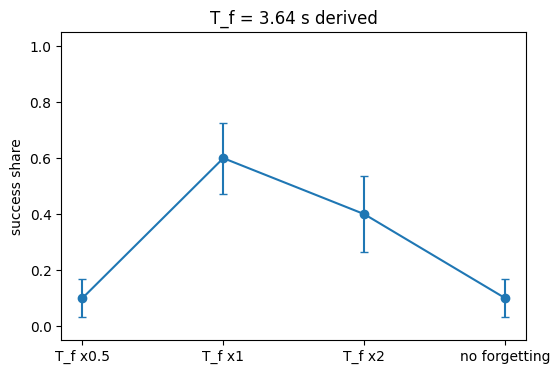

In [5]:
TF = {f"T_f x{f}": (True, np.exp(-m.DT / (f * m.T_F))) for f in (0.5, 2)}
tf = experiment("forgetting_horizon", TF, offsets_d)
tf = {
    "T_f x0.5": tf["T_f x0.5"],
    "T_f x1": abl["expanding + forgetting"],
    "T_f x2": tf["T_f x2"],
    "no forgetting": abl["expanding, no forgetting"],
}
table(tf, offsets_d)

fig, a = plt.subplots(figsize=(6, 4))
s = [shares(R)[:, 0] for R in tf.values()]
a.errorbar(
    list(tf),
    [v.mean() for v in s],
    [v.std(ddof=1) / np.sqrt(len(v)) for v in s],
    marker="o",
    capsize=3,
)
a.set(ylabel="success share", ylim=(-0.05, 1.05), title=f"T_f = {m.T_F:.2f} s derived")
plt.show()

### 3. Offset sweep
From the taught world, through offsets within the clearance ($\pm 0.015$), to beyond it. Each offset has its own sequences.

offset_sweep: 54 sequences in 5.9 min


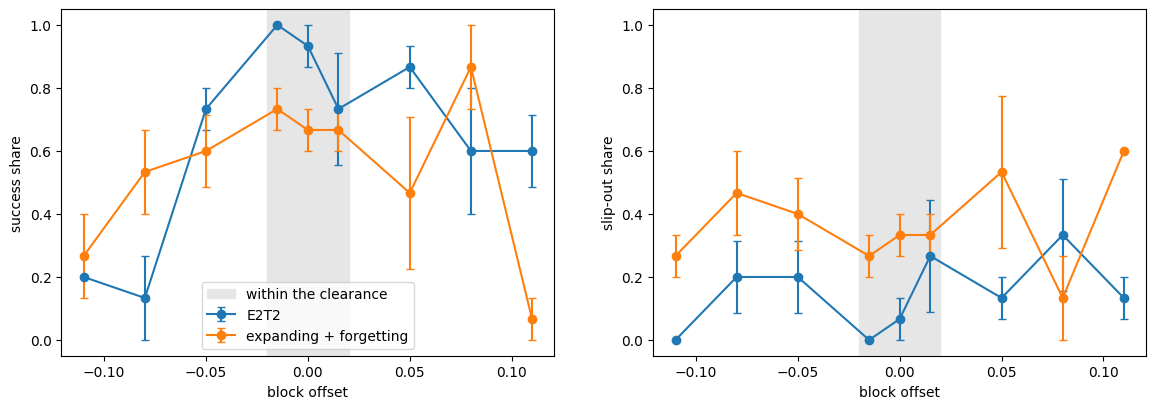

offset -0.110: E2T2 0.20, expanding + forgetting 0.27
offset -0.080: E2T2 0.13, expanding + forgetting 0.53
offset -0.050: E2T2 0.73, expanding + forgetting 0.60
offset -0.015: E2T2 1.00, expanding + forgetting 0.73
offset +0.000: E2T2 0.93, expanding + forgetting 0.67
offset +0.015: E2T2 0.73, expanding + forgetting 0.67
offset +0.050: E2T2 0.87, expanding + forgetting 0.47
offset +0.080: E2T2 0.60, expanding + forgetting 0.87
offset +0.110: E2T2 0.60, expanding + forgetting 0.07


In [6]:
GRID = np.array([-0.11, -0.08, -0.05, -0.015, 0.0, 0.015, 0.05, 0.08, 0.11])
offsets_s = np.repeat(GRID, N_SEQ_SWEEP)
sweep = experiment("offset_sweep", m.METHODS, offsets_s)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for k, R in sweep.items():
    s = shares(R)
    for a, j in zip(ax, (0, 1), strict=True):
        per = np.array([s[offsets_s == o, j] for o in GRID])
        se = per.std(1, ddof=1) / np.sqrt(N_SEQ_SWEEP) if N_SEQ_SWEEP > 1 else None
        a.errorbar(GRID, per.mean(1), se, marker="o", capsize=3, label=k)
for a, lbl in zip(ax, ("success share", "slip-out share"), strict=True):
    a.axvspan(-m.CLEAR, m.CLEAR, color="0.9", label="within the clearance")
    a.set(xlabel="block offset", ylabel=lbl, ylim=(-0.05, 1.05))
ax[0].legend()
plt.show()

for o in GRID:
    sel = offsets_s == o
    print(
        f"offset {o:+.3f}: "
        + ", ".join(f"{k} {shares(R[sel])[:, 0].mean():.2f}" for k, R in sweep.items())
    )